# <font color="red"> $DIFERENCIAS$ $DIVIDIDAS$

Las $diferencias$ $divididas$ son un método numérico utilizado para calcular los coeficientes del polinomio interpolante en la fórmula de Newton.  Este enfoque es preferible sobre el método de Lagrange porque permite agregar nuevos nodos a la tabla de datos sin necesidad de recalcular todo el polinomio. 

El cálculo se basa en una relación recursiva donde la diferencia dividida de orden superior se obtiene restando diferencias de orden inferior y dividiendo por la distancia entre los puntos extremos involucrados. La notación estándar es 
$$f[x_0,x_1,...,x_k]$$ 
donde los coeficientes obtenidos forman la base para construir el polinomio 
$$P_{n-1}(x)$$ que interpola los datos proporcionados.

Es decir: 
$$f[x_i, x_{i+1},... , x_{i+k−1}, x_{i+k} ] = \frac {f [x_{i+1}, x_{i+2},... , x_{i+k} ] − f [x_{i}, x_{i+1},... , x_{i+k−1}]}{x_{i+k} − x_{i}}$$




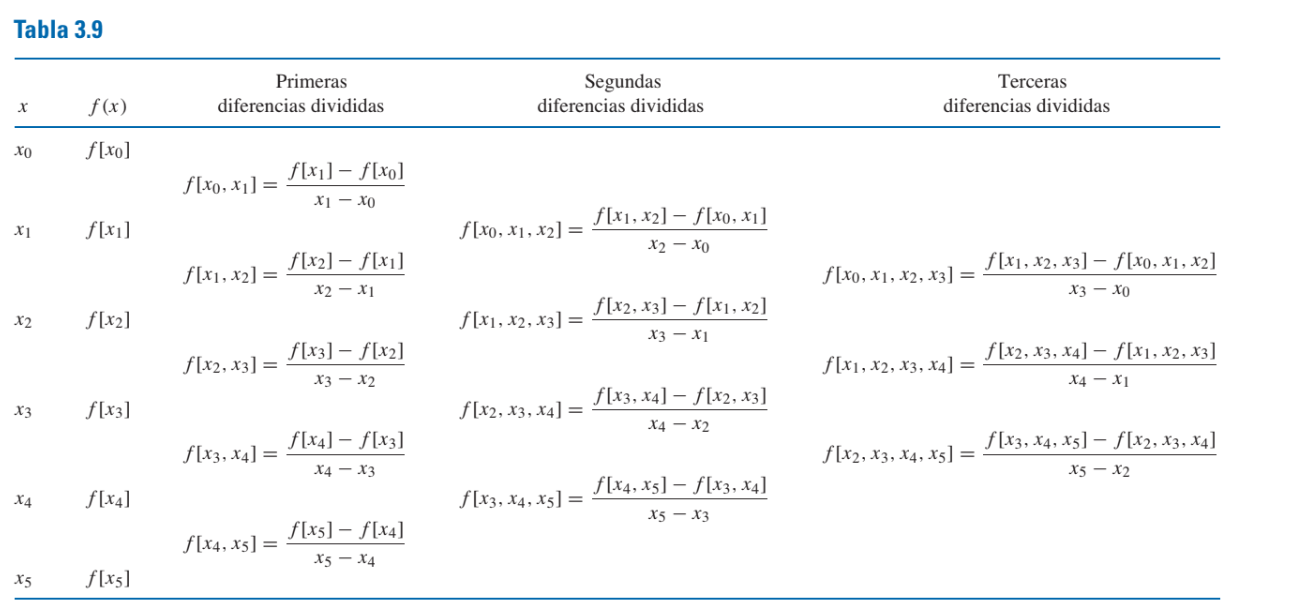

In [5]:
import sympy as sp

def newton_diferencias_divididas(x, y):
    n = len(x)
    # Matriz de n x n
    F = [[0.0 for _ in range(n)] for _ in range(n)]

    # ENTRADA: F_{i,0} = f(x_i)
    for i in range(n):
        F[i][0] = y[i]

    # Diferencias divididas
    for i in range(1, n):           # Para i = 1, 2, ..., n
        for j in range(1, i + 1):   # Para j = 1, 2, ..., i
            # F_{i,j} = (F_{i,j-1} - F_{i-1,j-1}) / (x_i - x_{i-j})
            numerador = F[i][j-1] - F[i-1][j-1]
            denominador = x[i] - x[i-j]
            F[i][j] = numerador / denominador

    # SALIDA: Extraemos los coeficientes de la diagonal (F_0,0, F_1,1, ..., F_n,n)
    coeficientes = [F[i][i] for i in range(n)]

    return F, coeficientes

In [6]:
def construir_y_graficar_polinomio(x_nodos, coeficientes):
    x = sp.Symbol('x')
    n = len(x_nodos)
    polinomio_newton = coeficientes[0]

    # Fórmula: P_n(x) = F_0,0 + sum( F_i,i * prod(x - x_j) )
    termino_producto = 1
    for i in range(1, n):
        termino_producto *= (x - x_nodos[i-1])
        polinomio_newton += coeficientes[i] * termino_producto

    polinomio_expandido = sp.expand(polinomio_newton)

    # Polinomio
    print("\n--- Polinomio en forma de Newton ---")
    sp.pprint(polinomio_newton)

    print("\n--- Polinomio expandido ---")
    sp.pprint(polinomio_expandido)

    # Graficar con SymPy
    print("\n--- Gráfica del Polinomio ---")
    rango_x = (x, min(x_nodos) - 0.2, max(x_nodos) + 0.2)
    grafico = sp.plot(
        polinomio_expandido,
        rango_x,
        title="Polinomio Interpolante de Newton (Ejemplo 1)",
        xlabel="x",
        ylabel="P_4(x)",
        line_color="green",
        show=True
    )

    return polinomio_expandido

In [7]:
def evaluar_en_x(x_eval, x_nodos, coeficientes):
    n = len(x_nodos)
    resultado = coeficientes[n-1]
    for i in range(n-2, -1, -1):
        resultado = resultado * (x_eval - x_nodos[i]) + coeficientes[i]
    return resultado

In [8]:
##### PRUEBA #####
if __name__ == "__main__":
    # Datos
    x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
    y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

    print("--- Tabla de Diferencias Divididas ---")
    tabla, coefs = newton_diferencias_divididas(x_datos, y_datos)

    # Imprimir tabla
    encabezado = f"{'xi':<5} | {'f(xi)':<11} | {'1ra Dif':<11} | {'2da Dif':<11} | {'3ra Dif':<11} | {'4ta Dif':<11}"
    print(encabezado)
    print("-" * len(encabezado))
    for i in range(len(x_datos)):
        fila = f"{x_datos[i]:<5.1f} |"
        for j in range(i + 1):
            fila += f" {tabla[i][j]:>10.7f} |"
        print(fila)

    print("\n--- Coeficientes del Polinomio (Diag F_i,i) ---")
    for i, c in enumerate(coefs):
        print(f"F_{i},{i} = {c:.7f}")

    # Construir y graficar el polinomio con SymPy
    polinomio = construir_y_graficar_polinomio(x_datos, coefs)

    # Comprobación
    print("\n--- Comprobación ---")
    x_eval = 1.5
    resultado = evaluar_en_x(x_eval, x_datos, coefs)
    print(f"P_4({x_eval}) = {resultado:.7f}  (Valor esperado en Burden: 0.5118200)")

--- Tabla de Diferencias Divididas ---
xi    | f(xi)       | 1ra Dif     | 2da Dif     | 3ra Dif     | 4ta Dif    
---------------------------------------------------------------------------
1.0   |  0.7651977 |
1.3   |  0.6200860 | -0.4837057 |
1.6   |  0.4554022 | -0.5489460 | -0.1087339 |
1.9   |  0.2818186 | -0.5786120 | -0.0494433 |  0.0658784 |
2.2   |  0.1103623 | -0.5715210 |  0.0118183 |  0.0680685 |  0.0018251 |

--- Coeficientes del Polinomio (Diag F_i,i) ---
F_0,0 = 0.7651977
F_1,1 = -0.4837057
F_2,2 = -0.1087339
F_3,3 = 0.0658784
F_4,4 = 0.0018251

--- Polinomio en forma de Newton ---
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

--- Polinomio expandido ---
                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪